# Direct anomaly detection for P-1

This notebook will fit an anomaly detector using P-1's supplied training readings, without supplying anomaly labels during fitting

This notebook will first use the current reading alone, then investigate whether recent hisotry features improve detection

The trainning sequence will be divided chronologically into fitting and validation portions. The supplied test readings will be used to evaluate alerts after development chouces are fixed


In [3]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd

dataset_dir = Path(
    "/home/diegorios/.cache/kagglehub/datasets/"
    "patrickfleith/nasa-anomaly-detection-dataset-smap-msl/versions/1"
)


# Load the supplied training readings for model development
p1_train = np.load(
    dataset_dir / "data" / "data" / "train" / "P-1.npy"
)

# load the training set and split
telemetry = pd.Series(p1_train[:, 0], name="telemetry")

split = int(0.8 * len(telemetry))

# these lines preserve the chronological order since telemetry rows already time ordered
# first 80% of rows used for fitting 
# remaining 20% used for validation
fit_readings = telemetry.iloc[:split]
val_readings = telemetry.iloc[split:]

print("Fitting readings:", len(fit_readings))
print("Validation readings:", len(val_readings))

Fitting readings: 2297
Validation readings: 575


## Isolation Forrest simple baseline

Isolation forrest identifies unusual observations using tress that randomly select features and numerical cutoffs. These internal splpits are different from randomly dividing data into training and test sets

This notebook preserves chronological order. The model learns from earlier readings and is evaluated on later readings

##### NOTE: This first model uses only the current telemetry value in the sequence. It therefore detects unusual values without explicitly considering previous readings

In [4]:
from sklearn.ensemble import IsolationForest

# using .to_frame() converts a pd series into a one column data frame
# so for example (2297,) becomes (2297,1) -> so I have 2297 observations and 1 feature

X_fit = fit_readings.to_frame()
X_val = val_readings.to_frame()

baseline_model = IsolationForest(random_state=42)
baseline_model.fit(X_fit)

# baseline_model.score_samples(X_val) calculates how unusual each validation observation looks to the fitted model
# the convention of Isolation forrest is that lower scores mean more unusual observations
# the minus sign reverses that direction
# I am doing this because its easier to interpret (larger score means more unusual)

val_scores = -baseline_model.score_samples(X_val)

print("Validation observations scored:", len(val_scores))
pd.Series(val_scores, index=X_val.index, name="anomaly_score").describe()

Validation observations scored: 575


count    575.000000
mean       0.503346
std        0.067373
min        0.427125
25%        0.451163
50%        0.488526
75%        0.526328
max        0.746556
Name: anomaly_score, dtype: float64

#### As a visual, plot the validation scores alongside the readings to see which values the model considers unusual 

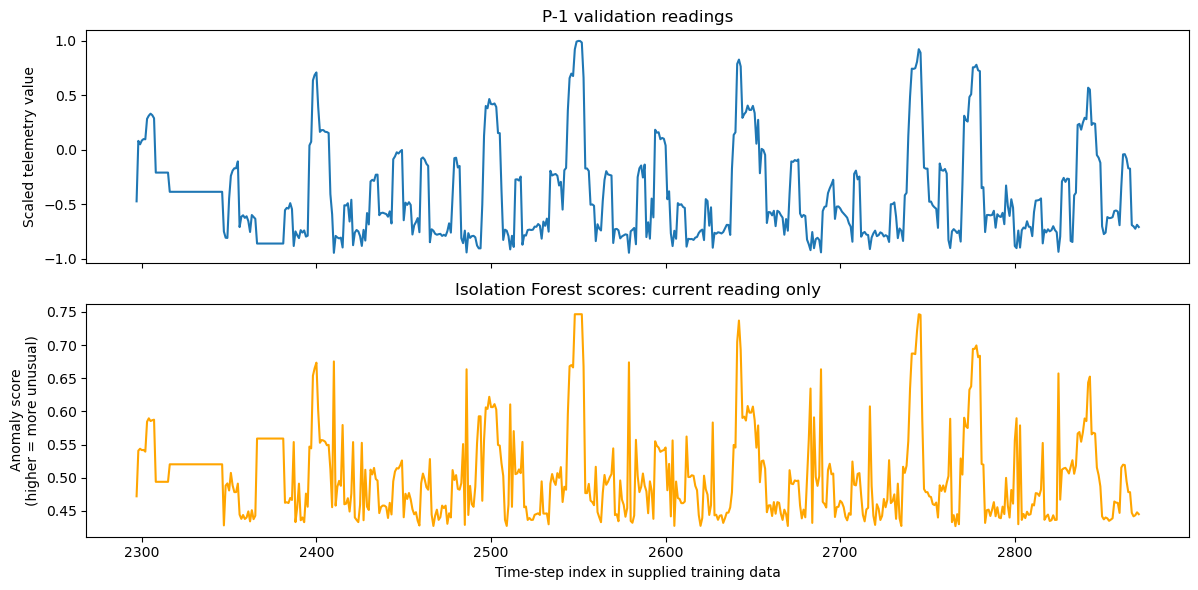

In [5]:
import matplotlib.pyplot as plt

val_score_series = pd.Series(
val_scores,
index = val_readings.index,
name = 'Anomaly score'
)

fig, axes = plt.subplots(2,1, figsize=(12,6), sharex=True)

axes[0].plot(val_readings.index, val_readings)
axes[0].set_ylabel("Scaled telemetry value")
axes[0].set_title("P-1 validation readings")

axes[1].plot(val_score_series.index, val_score_series, color="orange")
axes[1].set_xlabel("Time-step index in supplied training data")
axes[1].set_ylabel("Anomaly score\n(higher = more unusual)")
axes[1].set_title("Isolation Forest scores: current reading only")

plt.tight_layout()
plt.show()

#### Interpreting the baseline scores

The plot on the top shows the actual validation readings. The one on the bottom shows their Isolatiion Forrest Anomaly scores: higher scores mean the model considers a reading more unusual relative to the fitting data.


(Resued explanatoins from my EDA results)
Scaled telemetry value means the readings have been transformed into a numerical scale rather than shown in their original units, such as volts or degrees

The dataset creators scaled the telemetry using each channles test set minimum and maximum mapping them to -1 and +1

-1 represents the lowest recorded value

+1 represents the highest recorded value

0 is a midpoint betweeen those extremes

##### ( put simply, this shows us how high or low a reading is)

Several large upward excursions receieve high scores, while many readings near -0.8 recieve low scores

Flat streches recieve constant scores because identical input values recieve identical scores from this model

Again, this baseline has evaluated values individually and no alert threshold has been applied yet. This plots were made for quick inpsection of the model's behavior. Without anomaly labels for this validation portion they do not establish detection accuracy.

##### Next choose a threshold that turns scores into alerts

For the following initial example, I set the threshold at the 95th percentile of validation scores. This flags roughly the highest scoreing 5 percent (**this needs to be optimized somehow**)

In [8]:
alert_fraction = 0.05

baseline_threshold = val_score_series.quantile(1 - alert_fraction)

val_flags = val_score_series > baseline_threshold

print(f"Validation scores determined that: {baseline_threshold:.4f} is the 95th percentile")
print("Flagged validation readings:", val_flags.sum())
print(f"Percentage of validation scores flagged: {val_flags.mean():.1%}")

Validation scores determined that: 0.6592 is the 95th percentile
Flagged validation readings: 29
Percentage of validation scores flagged: 5.0%


##### Add threshold score to plots

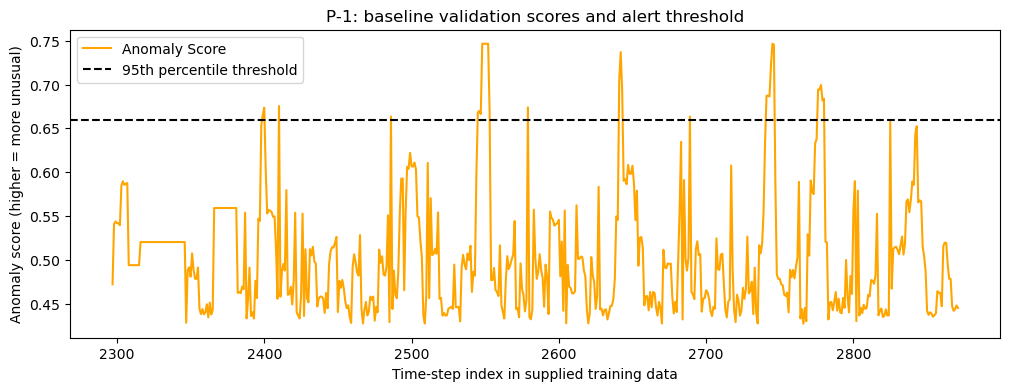

In [10]:
plt.figure(figsize = (12,4))

plt.plot(val_score_series.index,
        val_score_series,
        label = 'Anomaly Score',
        color = "Orange")

plt.axhline(
baseline_threshold,
color = 'black',
linestyle = '--',
label = '95th percentile threshold')

plt.xlabel("Time-step index in supplied training data")
plt.ylabel("Anomaly score (higher = more unusual)")
plt.title("P-1: baseline validation scores and alert threshold")
plt.legend()
plt.show()

#### What this baseline establishes 

Model fits using only the current P-1 telemetry value, meaning it does not yet account for any sort of relationship we would expect between readings over time

#### How would results change if we added recent history?

The following cells adds the previous two readings and the mean and standard deviation of the latest 10 readings (**still an initial experimental choice, not an optimized one**)

To organize the history features into a DataFrame, I have decided to use a dictionary

Each key will be a column name and the associated value supplies that columns data. So it looks something like this

| Time-step index | current | previous_1 | previous_2 | mean_10 | std_10 |
|---|---|---|---|---|---|
| \(t\) | Reading at \(t\) | Reading at \(t-1\) | Reading at \(t-2\) | Mean of latest 10 readings | Standard deviation of latest 10 readings |

In [11]:
# .shift() supplies previous readings
# .rolling(window=10) summarizes the current and previous 9 readings
# we also have to get far enough into the time seq to describe the history so, .dropna() removes rows containing any missing values

history_features = pd.DataFrame({
    'current': telemetry,
    'previous_1' : telemetry.shift(1),
    'previous_2' : telemetry.shift(2),
    'mean_10'    : telemetry.rolling(window=10).mean(),
    'std_10'     : telemetry.rolling(window=10).std()
}).dropna()

The following two lines divide the history features at the same time step boundary used in the baseline

In [12]:
# This selects all the rows before the split for fitting

X_fit_history = history_features.loc[history_features.index < split]

# This selects all the rows after the split for validatoin

X_val_history = history_features.loc[history_features.index >= split]

# essentually, creating features across the training seq before splitting

print("Fitting observations:", len(X_fit_history))
print("Validation observations:", len(X_val_history))

X_fit_history.head()

Fitting observations: 2288
Validation observations: 575


,current,previous_1,previous_2,mean_10,std_10
9,-0.193198,-0.214906,-0.756150,-0.532851,0.191623
10,-0.212012,-0.193198,-0.214906,-0.501737,0.216958
11,-0.204052,-0.212012,-0.193198,-0.453256,0.224533
12,-0.172214,-0.204052,-0.212012,-0.414978,0.237514
13,-0.719971,-0.172214,-0.204052,-0.433864,0.254664


# Now fit Isolation Forest using these history features and calculate its validation scores using the same alert rule from the simple baseline

In [14]:
history_model = IsolationForest(random_state=42)
history_model.fit(X_fit_history)

history_val_scores = pd.Series(
-history_model.score_samples(X_val_history),
index=X_val_history.index,
name='Anomaly Score')

history_threshold = history_val_scores.quantile(0.95)
history_val_flags = history_val_scores > history_threshold

print(f"Using history features the validation scores determined that: {history_threshold:.4f} is the 95th percentile")
print("Flagged validation readings:", history_val_flags.sum())
print(f"Percentage of validation scores flagged: {history_val_flags.mean():.1%}")



Using history features the validation scores determined that: 0.6199 is the 95th percentile
Flagged validation readings: 29
Percentage of validation scores flagged: 5.0%


### Plot both models of the same validation period

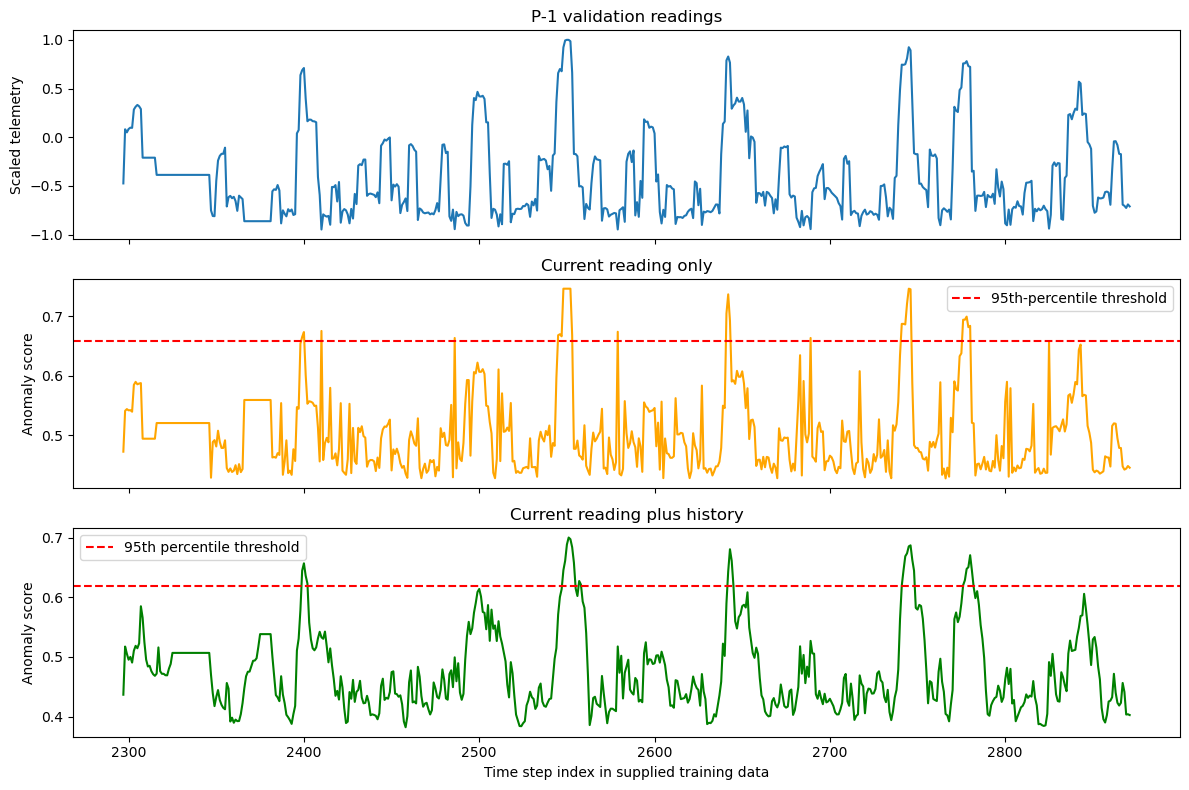

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(val_readings.index, val_readings)
axes[0].set_ylabel("Scaled telemetry")
axes[0].set_title("P-1 validation readings")

axes[1].plot(val_score_series.index, val_score_series, color="orange")
axes[1].axhline(baseline_threshold, color="red", linestyle="--",
                label="95th-percentile threshold")
axes[1].set_ylabel("Anomaly score")
axes[1].set_title("Current reading only")
axes[1].legend()

axes[2].plot(history_val_scores.index, history_val_scores, color="green")
axes[2].axhline(history_threshold, color="red", linestyle="--",
                label="95th percentile threshold")
axes[2].set_ylabel("Anomaly score")
axes[2].set_title("Current reading plus history")
axes[2].set_xlabel("Time step index in supplied training data")
axes[2].legend()

plt.tight_layout()
plt.show()

## Comparison of the baseline and history models 

Both models assign high scores to many of the same large telemetry excursions. Adding recent history features **(not optimized)** changes the score pattern, but does not seem to make flat streches anomalous.

Both thresholds were calibrated to flag approximately 5 percent of validation readings. The comparison therefore concerns which readings are selected, rather than how many alerts each model produces

In [17]:
from pathlib import Path
print(Path.cwd())

/home/diegorios/data-science
